In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 


In [9]:
df = pd.read_csv(r"C:\Users\musam\OneDrive\Desktop\Call_Center_Operations_Analytics\Data\call-center-performance.csv")

In [10]:
df.head()

,date,agent_id,queue_name,calls_handled,avg_handle_time_sec,avg_wait_time_sec,first_call_resolution_pct,csat_score,calls_abandoned,escalations
0,2023-07-28,AGT-0192,Retention,62,715,222,0.682,3.3,6.0,2.0
1,2024-11-18,AGT-0074,Activations,86,611,157,0.894,3.5,7.0,8.0
2,2024-10-16,AGT-0116,Complaints,29,886,44,0.548,2.8,1.0,1.0
3,2023-06-22,AGT-0074,Sales,71,862,108,0.762,4.4,9.0,2.0
4,2023-05-27,AGT-0109,Billing,44,123,105,0.655,2.6,1.0,4.0


In [12]:
df.shape

(1141, 10)

In [13]:
df.columns

Index(['date', 'agent_id', 'queue_name', 'calls_handled',
       'avg_handle_time_sec', 'avg_wait_time_sec', 'first_call_resolution_pct',
       'csat_score', 'calls_abandoned', 'escalations'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1141 entries, 0 to 1140
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       1141 non-null   object 
 1   agent_id                   1141 non-null   object 
 2   queue_name                 1141 non-null   object 
 3   calls_handled              1141 non-null   int64  
 4   avg_handle_time_sec        1141 non-null   int64  
 5   avg_wait_time_sec          1141 non-null   int64  
 6   first_call_resolution_pct  1141 non-null   float64
 7   csat_score                 1141 non-null   float64
 8   calls_abandoned            1140 non-null   float64
 9   escalations                1140 non-null   float64
dtypes: float64(4), int64(3), object(3)
memory usage: 89.3+ KB


In [15]:
df.describe()

,calls_handled,avg_handle_time_sec,avg_wait_time_sec,first_call_resolution_pct,csat_score,calls_abandoned,escalations
count,1141.000000,1141.000000,1141.000000,1141.000000,1141.000000,1140.000000,1140.000000
mean,63.991236,499.632778,160.574934,0.701168,3.753462,4.704386,2.992982
std,31.383674,241.254948,82.141998,0.145373,0.725584,4.082918,2.686085
min,10.000000,91.000000,15.000000,0.450000,2.500000,0.000000,0.000000
25%,36.000000,282.000000,90.000000,0.574000,3.100000,1.000000,1.000000
50%,62.000000,507.000000,159.000000,0.700000,3.700000,4.000000,2.000000
75%,92.000000,715.000000,230.000000,0.831000,4.400000,7.000000,5.000000
max,120.000000,900.000000,300.000000,0.950000,5.000000,17.000000,11.000000


In [16]:
df.isnull().sum()

date                         0
agent_id                     0
queue_name                   0
calls_handled                0
avg_handle_time_sec          0
avg_wait_time_sec            0
first_call_resolution_pct    0
csat_score                   0
calls_abandoned              1
escalations                  1
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['queue_name'].unique()

array(['Retention', 'Activations', 'Complaints', 'Sales', 'Billing',
       'Technical Support', 'General Enquiry'], dtype=object)

In [19]:
df_clean = df.copy()

In [21]:
df_clean['date'] = pd.to_datetime(df_clean['date'])

In [22]:
df_clean.dtypes

date                         datetime64[ns]
agent_id                             object
queue_name                           object
calls_handled                         int64
avg_handle_time_sec                   int64
avg_wait_time_sec                     int64
first_call_resolution_pct           float64
csat_score                          float64
calls_abandoned                     float64
escalations                         float64
dtype: object

In [23]:
df_clean.shape

(1141, 10)

In [24]:
df_clean['calls_handled'].sum()

np.int64(73014)

In [25]:
df_clean['avg_handle_time_sec'].mean()

np.float64(499.6327782646801)

In [26]:
df_clean['avg_wait_time_sec'].mean()

np.float64(160.5749342681858)

In [31]:
df_clean['first_call_resolution_pct'].mean()

np.float64(0.701168273444347)

In [30]:
df_clean['csat_score'].mean()

np.float64(3.7534618755477656)

In [32]:
df_clean['calls_abandoned'].sum()

np.float64(5363.0)

In [33]:
abandoment_rate = (
    df_clean['calls_abandoned'].sum()
    /(df_clean['calls_handled'].sum() + df_clean['calls_abandoned'].sum())
                  )
abandoment_rate 

np.float64(0.0684256861068936)

In [34]:
df_clean['escalations'].sum()

np.float64(3412.0)

In [35]:
escalation_rate = (
    df_clean['escalations'].sum()
    /df_clean['calls_handled'].sum()
)
escalation_rate

np.float64(0.04673076396307557)

In [36]:
calls_by_queue = (
    df_clean.groupby('queue_name')['calls_handled']
    .sum()
    .sort_values(ascending=False)
)
calls_by_queue

queue_name
Sales                11510
General Enquiry      11469
Billing              10982
Activations          10709
Retention            10551
Complaints            9964
Technical Support     7829
Name: calls_handled, dtype: int64

In [37]:
aht_by_queue = (
    df_clean.groupby('queue_name')['avg_handle_time_sec']
    .mean()
    .sort_values(ascending=False)
)
aht_by_queue

queue_name
Sales                526.870787
Billing              522.993902
General Enquiry      502.802260
Retention            499.321212
Technical Support    494.037037
Activations          479.128834
Complaints           467.610063
Name: avg_handle_time_sec, dtype: float64

In [38]:
wait_by_queue = (
    df_clean.groupby('queue_name')['avg_wait_time_sec']
    .mean()
    .sort_values(ascending=False)
)
wait_by_queue

queue_name
General Enquiry      172.135593
Activations          163.736196
Technical Support    161.370370
Billing              161.292683
Retention            157.066667
Sales                155.977528
Complaints           151.836478
Name: avg_wait_time_sec, dtype: float64

In [39]:
fcr_by_queue = (
    df_clean.groupby('queue_name')['first_call_resolution_pct']
    .mean()
    .sort_values(ascending=False)
)
fcr_by_queue

queue_name
Retention            0.707988
General Enquiry      0.705373
Complaints           0.705289
Sales                0.704303
Billing              0.702348
Activations          0.700245
Technical Support    0.678015
Name: first_call_resolution_pct, dtype: float64

In [40]:
csat_by_queue = (
    df_clean.groupby('queue_name')['csat_score']
    .mean()
    .sort_values(ascending=False)
)
csat_by_queue

queue_name
Technical Support    3.794815
Sales                3.778652
Activations          3.771779
Retention            3.757576
Complaints           3.746541
Billing              3.743293
General Enquiry      3.691525
Name: csat_score, dtype: float64

In [41]:
abandoned_by_queue = (
    df_clean.groupby('queue_name')['calls_abandoned']
    .sum()
    .sort_values(ascending=False)
)
abandoned_by_queue

queue_name
Billing              876.0
Sales                857.0
General Enquiry      810.0
Retention            770.0
Complaints           755.0
Activations          727.0
Technical Support    568.0
Name: calls_abandoned, dtype: float64

In [52]:
abandoment_by_queue = (
    df_clean.groupby('queue_name')
    .agg(
        calls_handled=('calls_handled', 'sum'),
        calls_abandoned=('calls_abandoned','sum')
    )
)
abandoment_by_queue['abandoment_rate'] = (
    abandoment_by_queue['calls_abandoned']
    /(abandoment_by_queue)['calls_handled']+
    abandoment_by_queue['calls_abandoned']
)
abandonment_by_queue.sort_values(
    'abandonment_rate',
    ascending=False
)

NameError: name 'abandonment_by_queue' is not defined

In [53]:
abandonment_by_queue = (
    df_clean.groupby('queue_name')
    .agg(
        calls_handled=('calls_handled', 'sum'),
        calls_abandoned=('calls_abandoned', 'sum')
    )
)

abandonment_by_queue['abandonment_rate'] = (
    abandonment_by_queue['calls_abandoned']
    / (
        abandonment_by_queue['calls_handled']
        + abandonment_by_queue['calls_abandoned']
    )
)

abandonment_by_queue.sort_values(
    'abandonment_rate',
    ascending=False
)

,calls_handled,calls_abandoned,abandonment_rate
queue_name,,,
Billing,10982,876.0,0.073874
Complaints,9964,755.0,0.070436
Sales,11510,857.0,0.069297
Retention,10551,770.0,0.068015
Technical Support,7829,568.0,0.067643
General Enquiry,11469,810.0,0.065966
Activations,10709,727.0,0.063571


In [54]:
escalation_by_queue = (
    df_clean.groupby('queue_name')
    .agg(
        calls_handled=('calls_handled', 'sum'),
        escalations=('escalations', 'sum')
    )
)

escalation_by_queue['escalation_rate'] = (
    escalation_by_queue['escalations']
    / escalation_by_queue['calls_handled']
)

escalation_by_queue.sort_values(
    'escalation_rate',
    ascending=False
)

,calls_handled,escalations,escalation_rate
queue_name,,,
General Enquiry,11469,581.0,0.050658
Sales,11510,557.0,0.048393
Complaints,9964,468.0,0.046969
Activations,10709,500.0,0.046690
Retention,10551,492.0,0.046631
Billing,10982,481.0,0.043799
Technical Support,7829,333.0,0.042534


In [55]:
queue_summary = (
    df_clean.groupby('queue_name')
    .agg(
        total_calls=('calls_handled', 'sum'),
        avg_handle_time=('avg_handle_time_sec', 'mean'),
        avg_wait_time=('avg_wait_time_sec', 'mean'),
        avg_fcr=('first_call_resolution_pct', 'mean'),
        avg_csat=('csat_score', 'mean'),
        total_abandoned=('calls_abandoned', 'sum'),
        total_escalations=('escalations', 'sum')
    )
)

queue_summary

,total_calls,avg_handle_time,avg_wait_time,avg_fcr,avg_csat,total_abandoned,total_escalations
queue_name,,,,,,,
Activations,10709,479.128834,163.736196,0.700245,3.771779,727.0,500.0
Billing,10982,522.993902,161.292683,0.702348,3.743293,876.0,481.0
Complaints,9964,467.610063,151.836478,0.705289,3.746541,755.0,468.0
General Enquiry,11469,502.802260,172.135593,0.705373,3.691525,810.0,581.0
Retention,10551,499.321212,157.066667,0.707988,3.757576,770.0,492.0
Sales,11510,526.870787,155.977528,0.704303,3.778652,857.0,557.0
Technical Support,7829,494.037037,161.370370,0.678015,3.794815,568.0,333.0


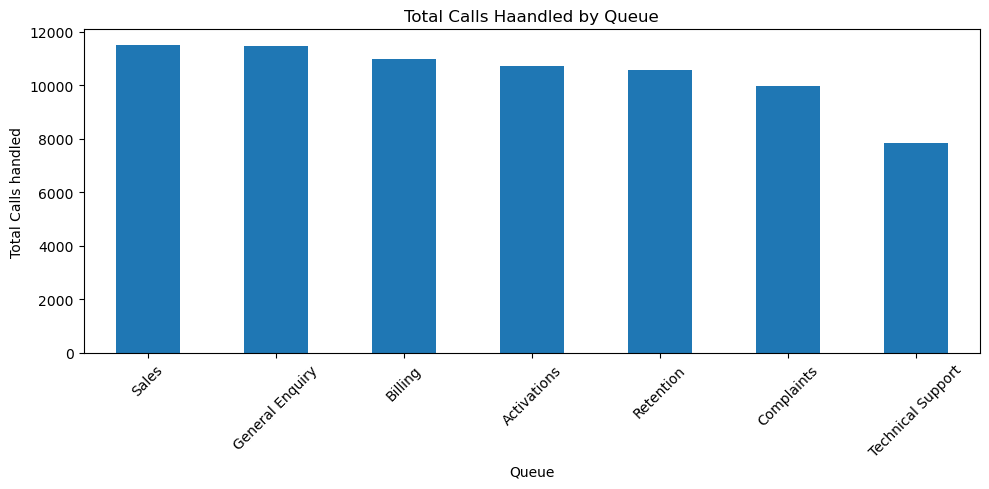

In [56]:
plt.figure(figsize=(10,5))
calls_by_queue.plot(kind='bar')
plt.title('Total Calls Handled by Queue')
plt.xlabel('Queue')
plt.ylabel('Total Calls handled')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

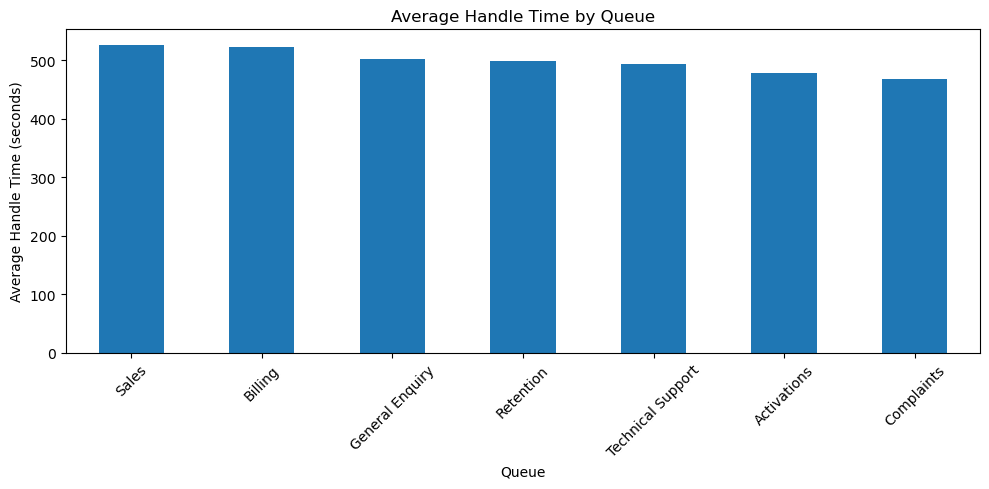

In [58]:
plt.figure(figsize=(10,5))
aht_by_queue.plot(kind='bar')
plt.title('Average Handle Time by Queue')
plt.xlabel('Queue')
plt.ylabel('Average Handle Time (seconds)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

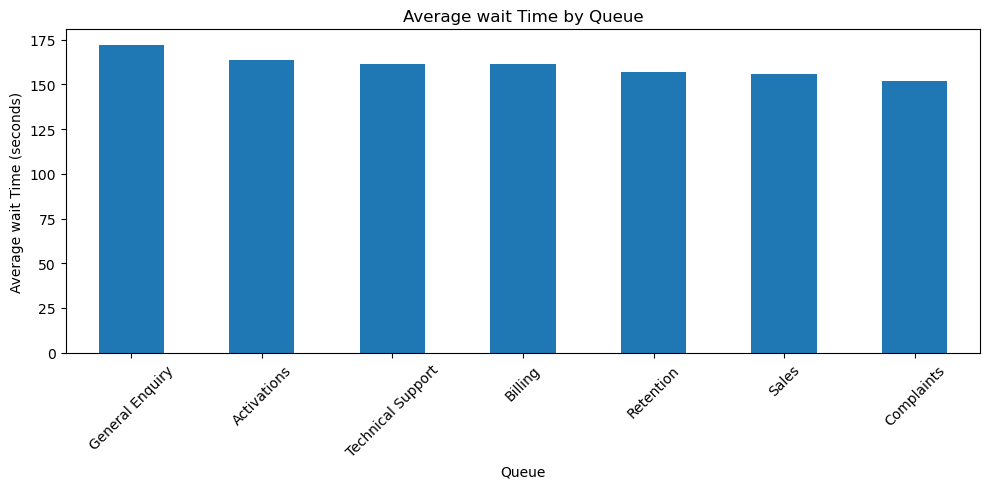

In [59]:
plt.figure(figsize=(10,5))
wait_by_queue.plot(kind='bar')
plt.title('Average wait Time by Queue')
plt.xlabel('Queue')
plt.ylabel('Average wait Time (seconds)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

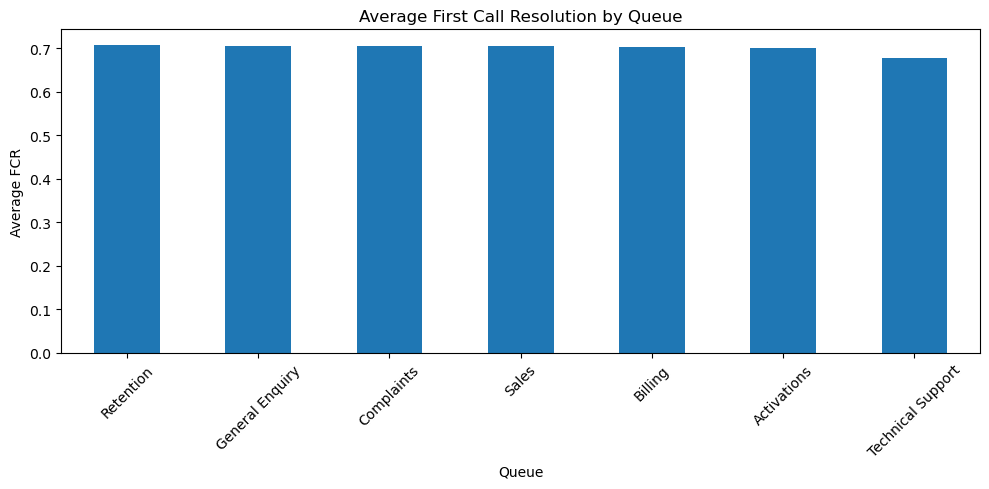

In [60]:
plt.figure(figsize=(10,5))
fcr_by_queue.plot(kind='bar')
plt.title('Average First Call Resolution by Queue')
plt.xlabel('Queue')
plt.ylabel('Average FCR')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

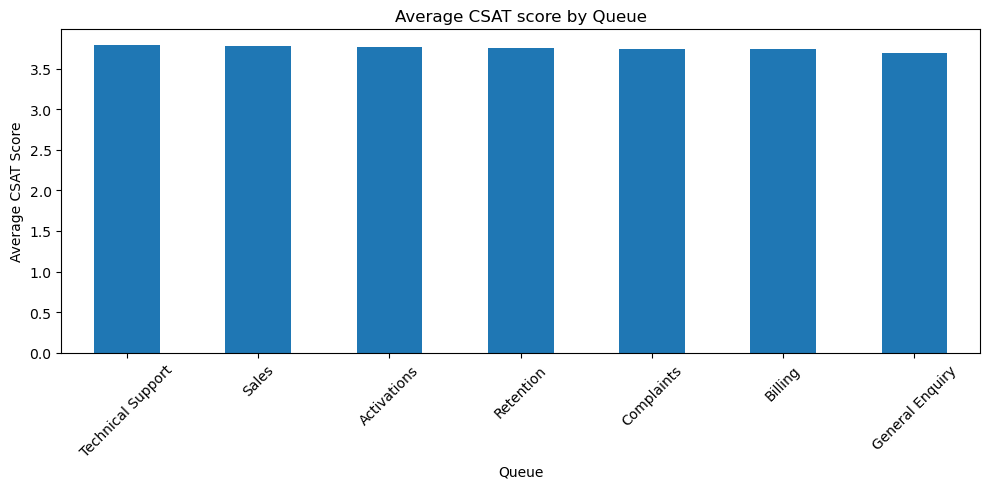

In [61]:
plt.figure(figsize=(10,5))
csat_by_queue.plot(kind='bar')
plt.title('Average CSAT score by Queue')
plt.xlabel('Queue')
plt.ylabel('Average CSAT Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

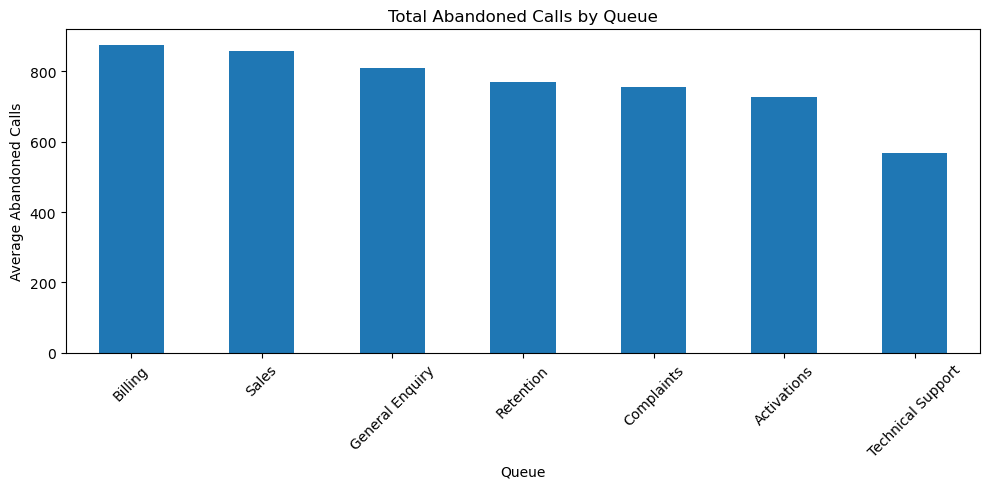

In [62]:
plt.figure(figsize=(10,5))
abandoned_by_queue.plot(kind='bar')
plt.title('Total Abandoned Calls by Queue')
plt.xlabel('Queue')
plt.ylabel('Average Abandoned Calls')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

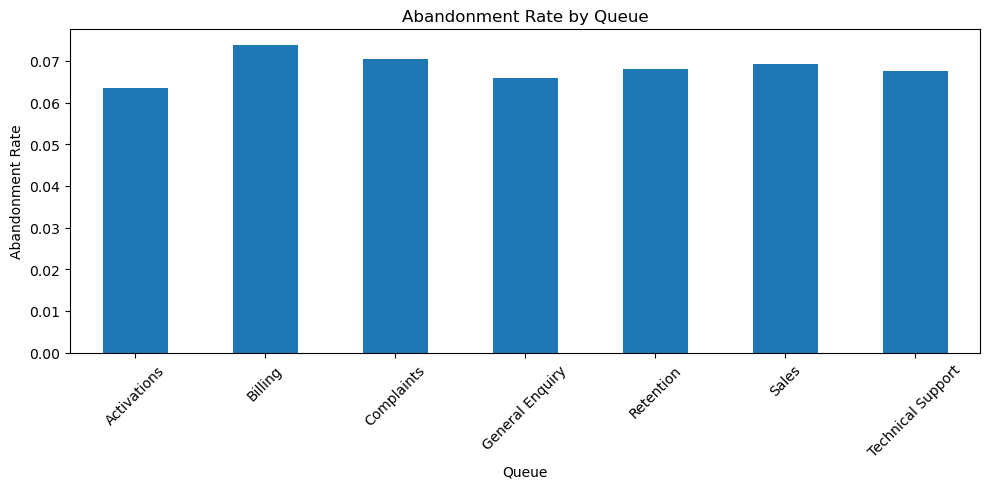

In [63]:
plt.figure(figsize=(10,5))
abandonment_by_queue['abandonment_rate'].plot(kind='bar')
plt.title('Abandonment Rate by Queue')
plt.xlabel('Queue')
plt.ylabel('Abandonment Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

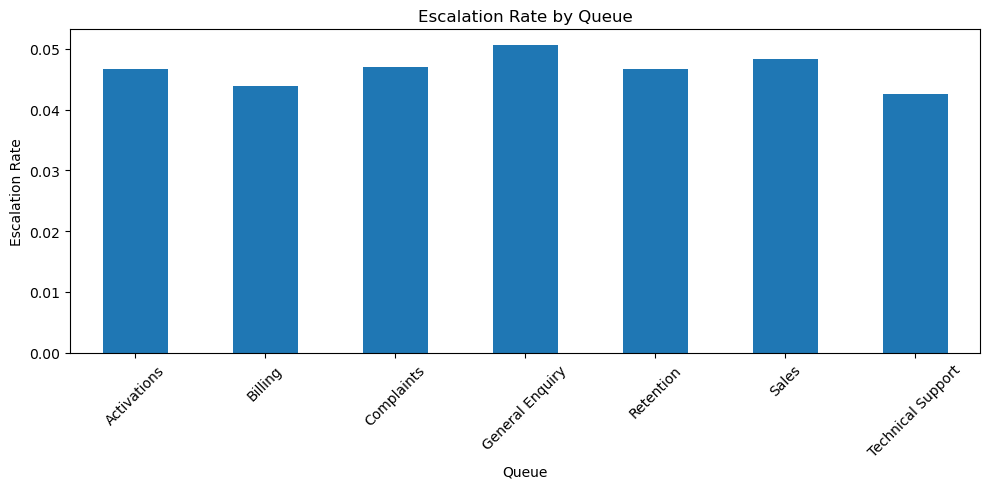

In [64]:
plt.figure(figsize=(10,5))
escalation_by_queue['escalation_rate'].plot(kind='bar')
plt.title('Escalation Rate by Queue')
plt.xlabel('Queue')
plt.ylabel('Escalation Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()